# OPTIMIZING PUBLIC TRANSIT OPERATIONS
An Exploratory Data Analysis of Public Transportation

### About Company
MetroMove Transit Solutions is a public transportation service provider operating in multiple cities. 
They manage and analyze thousands of daily trips taken via buses, trains, ferries, and trams. 
The company's mission is to provide efficient, affordable, and timely public transportation services while leveraging data to improve passenger experience and optimize operations.

### Recent Challenges:
 - Messy, inconsistent, and incomplete records
 - Lack of insight into the large volume of trip data collected.

### Aim:
 - Data Cleaning
 - Understanding passenger usage patterns.
 - Analyzing how trip characteristics impact customer experience.
 - Evaluating the performance of different transport modes.
 

### Tools
**`Numpy`|`Pandas`| `Matplotlib`| `Seaborn`|**



### Data  Description 
 `Column`| `Description`
- Trip_ID: Unique identifier for each trip
- Mode_of_Transport: Type of transport used: Bus, Train, Ferry, or Tram (includes inconsistencies)
- Departure_Station: Station where the trip starts (contains whitespace errors)
- Arrival_Station: Station where the trip ends (inconsistent casing)
- Departure_Time: Exact date and time when the trip departed
- Passenger_Count: Number of passengers on the trip (includes missing values)
- Fare_Amount:  Amount paid by the passengers for the trip (includes missing values)
- Trip_Duration_Minutes: Duration of the trip in minutes (includes missing values)
- Trip_Date: Date on which the trip occurred
- Day_of_Week: Day of the week on which the trip occurred


In [1]:
# Importing libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno

In [2]:
# Loading Dataset
df = pd.read_excel(r"Public_Transport_Trips_EDA.xlsx")

In [3]:
df.head()

,Trip_ID,Mode_of_Transport,Departure_Station,Arrival_Station,Departure_Time,Passenger_Count,Fare_Amount,Trip_Duration_Minutes,Trip_Date,Day_of_Week,Unnamed: 10,Unnamed: 11
0,TRIP0001,FERRY,West End,airport,2024-01-01 06:00:00,21.0,4.343642,26.0,2024-01-01,Sunday,NaN,F
1,TRIP0002,Tram,North Station,Downtown,2024-01-01 06:01:00,46.0,20.673380,134.0,2024-01-01,Saturday,NaN,F
2,TRIP0003,bus,Central,North Station,2024-01-01 06:02:00,91.0,NaN,NaN,2024-01-01,Tuesday,NaN,F
3,TRIP0004,FERRY,Downtown,Central,2024-01-01 06:03:00,27.0,3.767487,NaN,2024-01-01,Sunday,NaN,F
4,TRIP0005,Ferry,Downtown,Central,2024-01-01 06:04:00,66.0,NaN,NaN,2024-01-01,Monday,NaN,F


### Data Validation

In [4]:
# Checking the general information of the dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 12 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   Trip_ID                1000 non-null   object        
 1   Mode_of_Transport      1000 non-null   object        
 2   Departure_Station      1000 non-null   object        
 3   Arrival_Station        1000 non-null   object        
 4   Departure_Time         1000 non-null   datetime64[ns]
 5   Passenger_Count        900 non-null    float64       
 6   Fare_Amount            900 non-null    float64       
 7   Trip_Duration_Minutes  900 non-null    float64       
 8   Trip_Date              1000 non-null   datetime64[ns]
 9   Day_of_Week            1000 non-null   object        
 10  Unnamed: 10            0 non-null      float64       
 11  Unnamed: 11            299 non-null    object        
dtypes: datetime64[ns](2), float64(4), object(6)
memory usage: 93.9+

In [5]:
# Checking the contents in 'Unnamed: 11' column

df['Unnamed: 11'].value_counts()

Unnamed: 11
F    250
T     49
Name: count, dtype: int64

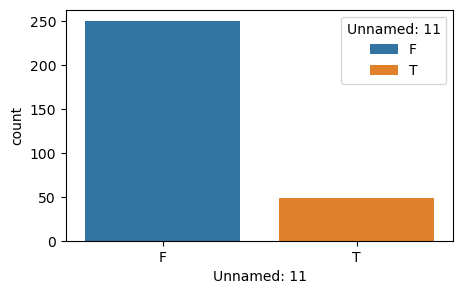

In [6]:
plt.figure(figsize=(5,3))
sns.countplot(x='Unnamed: 11', data=df, hue='Unnamed: 11');

#### Observation
Column "Unnamed: 11" has 299 non-null values out of 999 expected. Nothing much can be extracted from it.
- "Unnamed: 11" & "Unnamed: 10"  will be dropped.

In [7]:
# Deleting columns 'Unnamed: 10 ' and Unnamed: 11
df.drop(['Unnamed: 10', 'Unnamed: 11'] , axis=1, inplace=True)

In [8]:
df.head(2)

,Trip_ID,Mode_of_Transport,Departure_Station,Arrival_Station,Departure_Time,Passenger_Count,Fare_Amount,Trip_Duration_Minutes,Trip_Date,Day_of_Week
0,TRIP0001,FERRY,West End,airport,2024-01-01 06:00:00,21.0,4.343642,26.0,2024-01-01,Sunday
1,TRIP0002,Tram,North Station,Downtown,2024-01-01 06:01:00,46.0,20.673380,134.0,2024-01-01,Saturday


In [9]:
# Validating unique 'Trip_ID' and checking for duplicated rows

len(df['Trip_ID'].unique())

1000

In [10]:
df.duplicated().sum()

np.int64(0)

### Data Cleaning and handling inconsitencies

In [11]:
df.columns

Index(['Trip_ID', 'Mode_of_Transport', 'Departure_Station', 'Arrival_Station',
       'Departure_Time', 'Passenger_Count', 'Fare_Amount',
       'Trip_Duration_Minutes', 'Trip_Date', 'Day_of_Week'],
      dtype='object')

In [12]:
df['Mode_of_Transport'].value_counts()

Mode_of_Transport
Bus      147
Tram     138
bus      137
train    123
Train    120
FERRY    119
Ferry    118
fErry     50
BUS       48
Name: count, dtype: int64

In [13]:
# Removing whitespaces and converting individual entries to title string format
df['Mode_of_Transport'] = df['Mode_of_Transport'].str.strip().str.title()

In [14]:
df['Mode_of_Transport'].value_counts()

Mode_of_Transport
Bus      332
Ferry    287
Train    243
Tram     138
Name: count, dtype: int64

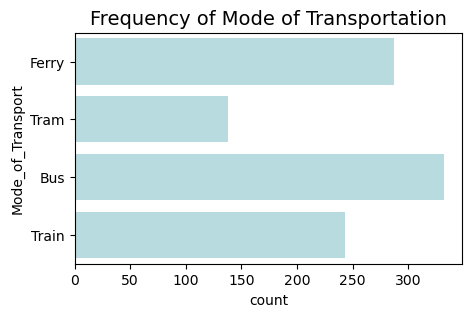

In [15]:
plt.figure(figsize=(5,3))
sns.countplot(df['Mode_of_Transport'], color='powderblue')
plt.title('Frequency of Mode of Transportation', fontsize=14);

#### Insight:
**Bus** is the most frequent mode of transportation while the least is **Tram**

In [16]:
df['Departure_Station'].value_counts()

Departure_Station
North Station    171
Downtown         167
West End         159
Central          158
Airport          157
South Point      138
 Central          50
Name: count, dtype: int64

In [17]:
# Removing whitespaces in 'Departure_Station
df['Departure_Station'] = df['Departure_Station'].str.strip()

In [18]:
df['Departure_Station'].value_counts()

Departure_Station
Central          208
North Station    171
Downtown         167
West End         159
Airport          157
South Point      138
Name: count, dtype: int64

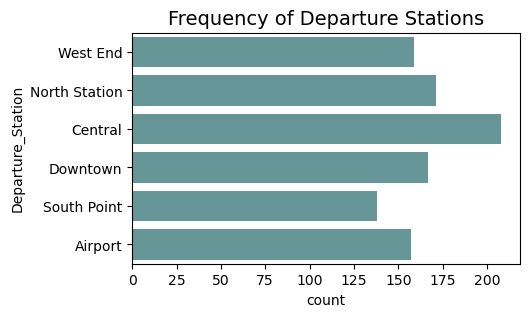

In [19]:
plt.figure(figsize=(5,3))
sns.countplot(df['Departure_Station'], color='cadetblue')
plt.title('Frequency of Departure Stations', fontsize=14);

#### Insight:
**Central** expenrienced the highest number of transportation departures while **South Point** has the least

In [20]:
df['Arrival_Station'].value_counts()

Arrival_Station
South Point      171
Downtown         168
West End         163
Airport          163
Central          160
North Station    125
airport           50
Name: count, dtype: int64

In [21]:
# Removing whitespaces and stadardizing unique entries in 'Arrival_Station'

df['Arrival_Station'] = df['Arrival_Station'].str.strip().str.title()

In [22]:
df['Arrival_Station'].value_counts()

Arrival_Station
Airport          213
South Point      171
Downtown         168
West End         163
Central          160
North Station    125
Name: count, dtype: int64

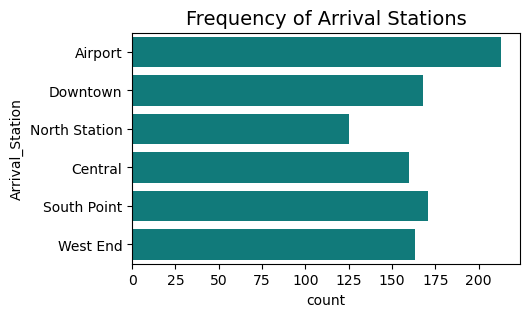

In [23]:
plt.figure(figsize=(5,3))
sns.countplot(df['Arrival_Station'], color='darkcyan')
plt.title('Frequency of Arrival Stations', fontsize=14);

#### Insight:
**Airpot** has the highest number of arrivals while **North Station** has the least arrivals.

In [24]:
# Checking percentage of missing data across the columns

In [25]:
df.isna().mean()*100

Trip_ID                   0.0
Mode_of_Transport         0.0
Departure_Station         0.0
Arrival_Station           0.0
Departure_Time            0.0
Passenger_Count          10.0
Fare_Amount              10.0
Trip_Duration_Minutes    10.0
Trip_Date                 0.0
Day_of_Week               0.0
dtype: float64

#### Exploring the Missing data through visualization

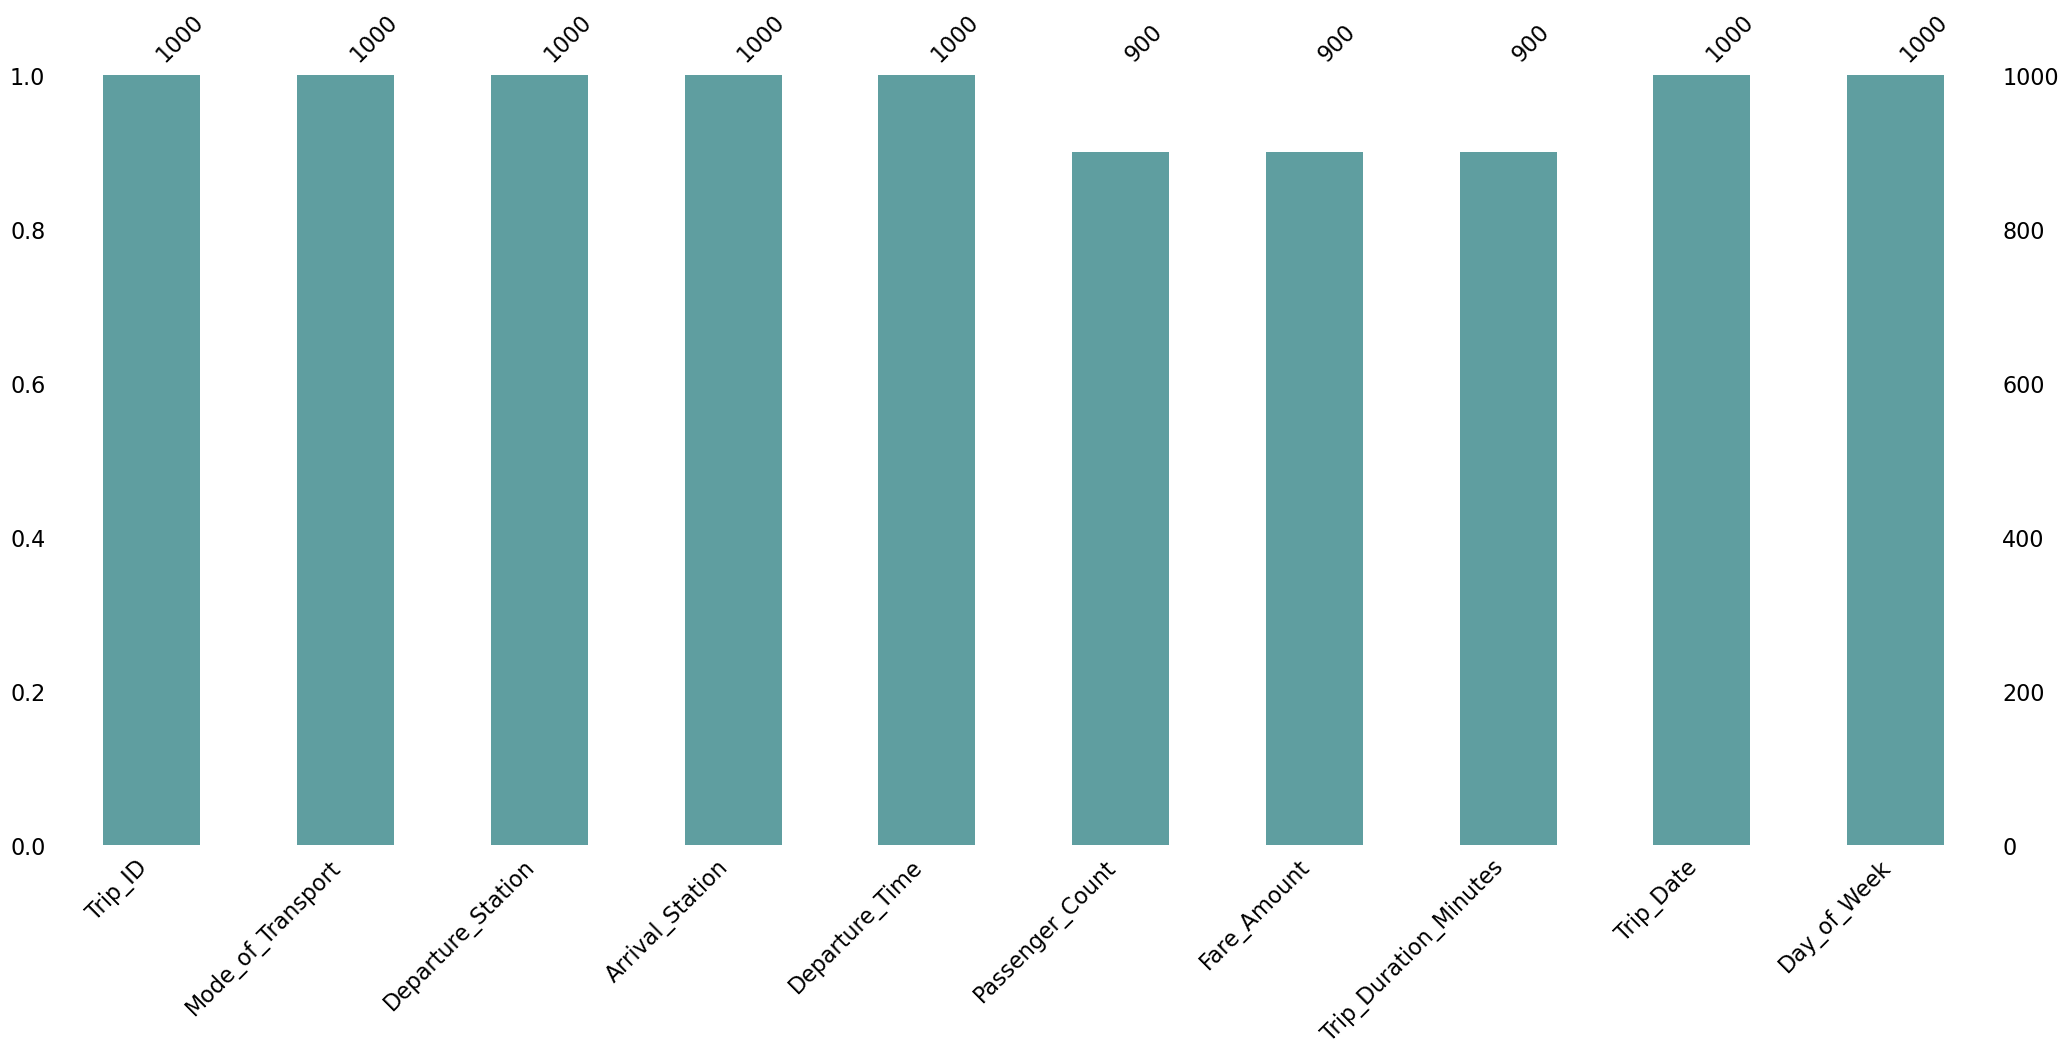

In [26]:
# Visualizing with misingno 
plt.figure(figsize=(6,3))
msno.bar(df, color="cadetblue");

Text(0.5, 1.0, 'Heatmap Visualization of Missing Data')

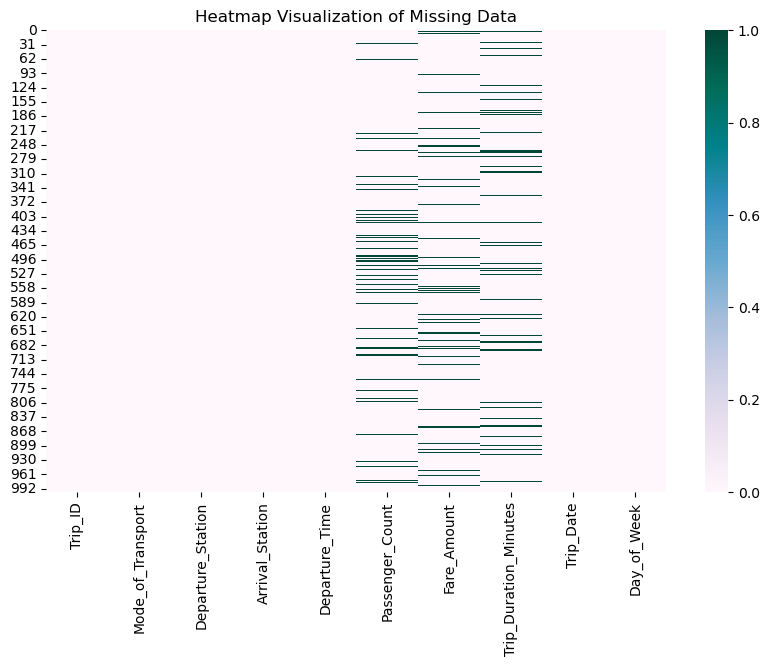

In [27]:
#Using a Heat map
plt.figure(figsize=(10, 6))
sns.heatmap(df.isnull(), cbar=True, cmap="PuBuGn");
plt.title("Heatmap Visualization of Missing Data")

#### Insight
Columns with missing data are **Passenger_Count, Fare_Amount, Trip_Duration_Minutes**
- About **10%** of the data are missing in each column and are also evenly distributed across the entire dataset

### Filling in Missing data

In [28]:
# Overview of all numerical data
df.describe().round(2)

,Departure_Time,Passenger_Count,Fare_Amount,Trip_Duration_Minutes,Trip_Date
count,1000,900.00,900.00,900.00,1000
mean,2024-01-01 14:19:30,49.15,25.36,94.27,2024-01-21 08:03:50.400000
min,2024-01-01 06:00:00,1.00,0.50,5.00,2024-01-01 00:00:00
25%,2024-01-01 10:09:45,25.00,12.82,49.75,2024-01-11 00:00:00
50%,2024-01-01 14:19:30,48.00,25.40,97.50,2024-01-21 00:00:00
75%,2024-01-01 18:29:15,72.00,37.87,138.00,2024-02-01 00:00:00
max,2024-01-01 22:39:00,99.00,49.95,179.00,2024-02-11 00:00:00
std,NaN,27.70,14.46,50.63,NaN


##### Checking the median of missing data by Mode of Transportation

In [29]:
# Median of 'Passenger_Count'
# .transform() --------- Calculates group medians aligned with the original rows

passenger_count_median = df.groupby('Mode_of_Transport')['Passenger_Count'].transform('median')

passenger_count_median

0      48.0
1      49.0
2      48.0
3      48.0
4      48.0
       ... 
995    45.5
996    48.0
997    48.0
998    49.0
999    45.5
Name: Passenger_Count, Length: 1000, dtype: float64

In [30]:
# Median of 'Fare_Amount'
# .to_frame() --------- Converts a Series into a DataFrame.
fare_amount_median = df.groupby('Mode_of_Transport')['Fare_Amount'].median().to_frame()

fare_amount_median

,Fare_Amount
Mode_of_Transport,
Bus,26.312252
Ferry,23.550152
Train,26.620035
Tram,25.293440


In [31]:
# Median of 'Trip_Duration_Minutes'
trip_duration_median = df.groupby('Mode_of_Transport')['Trip_Duration_Minutes'].transform('median')

trip_duration_median

0       93.0
1       94.0
2      100.0
3       93.0
4       93.0
       ...  
995     99.0
996    100.0
997     93.0
998     94.0
999     99.0
Name: Trip_Duration_Minutes, Length: 1000, dtype: float64

##### Handling Missing Numeric data with the median with respect to their Mode of transportation

In [32]:
df['Passenger_Count'] = df['Passenger_Count'].fillna(passenger_count_median)

# .map() e.g, looks up the corresponding median in fare_amount_median.
df['Fare_Amount'] = df['Fare_Amount'].fillna(df['Mode_of_Transport'].map(fare_amount_median['Fare_Amount']))

df['Trip_Duration_Minutes'] = df['Trip_Duration_Minutes'].fillna(trip_duration_median)

In [33]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   Trip_ID                1000 non-null   object        
 1   Mode_of_Transport      1000 non-null   object        
 2   Departure_Station      1000 non-null   object        
 3   Arrival_Station        1000 non-null   object        
 4   Departure_Time         1000 non-null   datetime64[ns]
 5   Passenger_Count        1000 non-null   float64       
 6   Fare_Amount            1000 non-null   float64       
 7   Trip_Duration_Minutes  1000 non-null   float64       
 8   Trip_Date              1000 non-null   datetime64[ns]
 9   Day_of_Week            1000 non-null   object        
dtypes: datetime64[ns](2), float64(3), object(5)
memory usage: 78.3+ KB


##### Converting 'Passenger_Count' column data from float to interger

In [34]:
df['Passenger_Count'] = df['Passenger_Count'].round().astype(int)
df['Fare_Amount'] = df['Fare_Amount'].round(2)

In [35]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   Trip_ID                1000 non-null   object        
 1   Mode_of_Transport      1000 non-null   object        
 2   Departure_Station      1000 non-null   object        
 3   Arrival_Station        1000 non-null   object        
 4   Departure_Time         1000 non-null   datetime64[ns]
 5   Passenger_Count        1000 non-null   int64         
 6   Fare_Amount            1000 non-null   float64       
 7   Trip_Duration_Minutes  1000 non-null   float64       
 8   Trip_Date              1000 non-null   datetime64[ns]
 9   Day_of_Week            1000 non-null   object        
dtypes: datetime64[ns](2), float64(2), int64(1), object(5)
memory usage: 78.3+ KB


### Extracting the date column

In [36]:
# Creating a new column for 'Trip Year Month'  using datetime(dt) to period (Month)

df['Trip_Year_Month'] = df['Trip_Date'].dt.to_period('M').astype(str)

In [37]:
df.sample(2, random_state=42)

,Trip_ID,Mode_of_Transport,Departure_Station,Arrival_Station,Departure_Time,Passenger_Count,Fare_Amount,Trip_Duration_Minutes,Trip_Date,Day_of_Week,Trip_Year_Month
521,TRIP0522,Bus,Airport,Downtown,2024-01-01 14:41:00,55,48.27,22.0,2024-01-22,Tuesday,2024-01
737,TRIP0738,Ferry,Airport,North Station,2024-01-01 18:17:00,48,44.19,160.0,2024-01-31,Thursday,2024-01


In [38]:
df['Trip_Year_Month'].value_counts()

Trip_Year_Month
2024-01    744
2024-02    256
Name: count, dtype: int64

### Extracting the actual Departure and Arrival time(hour) and grouping it.

In [39]:
#Extracting the departure hour from the departure time

df['Departure_hour'] = df['Departure_Time'].dt.hour 

df['Departure_hour'].value_counts()

Departure_hour
6     60
15    60
21    60
20    60
19    60
18    60
17    60
16    60
14    60
7     60
13    60
12    60
11    60
10    60
9     60
8     60
22    40
Name: count, dtype: int64

In [40]:
#Extracting the departure minutes from the departure time

df['Departure_Minutes'] = df['Departure_Time'].dt.minute

In [41]:
# Calculating Arrival Hour from Departure Minutes and Hour
# 60 minutes = 1hr

df['Arrival_hour'] = (df['Departure_Minutes'] + df['Trip_Duration_Minutes'])// 60 + df['Departure_hour']

In [42]:
df.head()

,Trip_ID,Mode_of_Transport,Departure_Station,Arrival_Station,Departure_Time,Passenger_Count,Fare_Amount,Trip_Duration_Minutes,Trip_Date,Day_of_Week,Trip_Year_Month,Departure_hour,Departure_Minutes,Arrival_hour
0,TRIP0001,Ferry,West End,Airport,2024-01-01 06:00:00,21,4.34,26.0,2024-01-01,Sunday,2024-01,6,0,6.0
1,TRIP0002,Tram,North Station,Downtown,2024-01-01 06:01:00,46,20.67,134.0,2024-01-01,Saturday,2024-01,6,1,8.0
2,TRIP0003,Bus,Central,North Station,2024-01-01 06:02:00,91,26.31,100.0,2024-01-01,Tuesday,2024-01,6,2,7.0
3,TRIP0004,Ferry,Downtown,Central,2024-01-01 06:03:00,27,3.77,93.0,2024-01-01,Sunday,2024-01,6,3,7.0
4,TRIP0005,Ferry,Downtown,Central,2024-01-01 06:04:00,66,23.55,93.0,2024-01-01,Monday,2024-01,6,4,7.0


#### Grouping departure hours into time bands

In [43]:
df['Departure_Time'].min()

Timestamp('2024-01-01 06:00:00')

In [44]:
df['Departure_Time'].max()

Timestamp('2024-01-01 22:39:00')

In [45]:
hour = df['Departure_hour']
hr_conditions = [ (hour >= 6) & (hour <= 9), hour <= 12, hour <= 16, hour <= 20, hour <= 23]
hr_labels = ['Early(06 - 09)', 'Morning(10 - 12)', 'Afternoon(13 - 16)', 'Evening(17 - 20)', 'Late(21 - 23)']

In [46]:
df['Time_band'] = np.select(hr_conditions, hr_labels, default="Mid-Night(00 - 05)")

In [47]:
df.sample(3)

,Trip_ID,Mode_of_Transport,Departure_Station,Arrival_Station,Departure_Time,Passenger_Count,Fare_Amount,Trip_Duration_Minutes,Trip_Date,Day_of_Week,Trip_Year_Month,Departure_hour,Departure_Minutes,Arrival_hour,Time_band
84,TRIP0085,Train,North Station,Central,2024-01-01 07:24:00,63,31.82,97.0,2024-01-04,Thursday,2024-01,7,24,9.0,Early(06 - 09)
950,TRIP0951,Ferry,South Point,Airport,2024-01-01 21:50:00,96,43.22,177.0,2024-02-09,Friday,2024-02,21,50,24.0,Late(21 - 23)
654,TRIP0655,Bus,North Station,West End,2024-01-01 16:54:00,40,26.31,92.0,2024-01-28,Monday,2024-01,16,54,18.0,Afternoon(13 - 16)


In [48]:
df['Time_band'].value_counts()

Time_band
Early(06 - 09)        240
Afternoon(13 - 16)    240
Evening(17 - 20)      240
Morning(10 - 12)      180
Late(21 - 23)         100
Name: count, dtype: int64

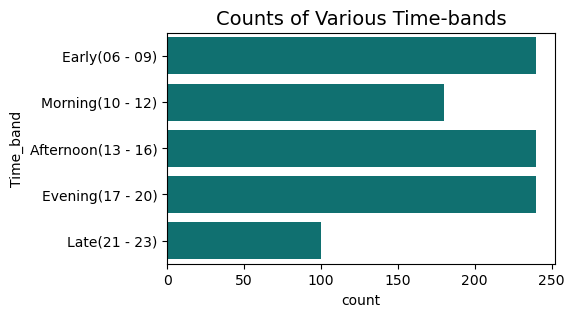

In [49]:
plt.figure(figsize=(5,3))
sns.countplot(df['Time_band'], color='teal')
plt.title("Counts of Various Time-bands", fontsize=14);

#### Insight:
**`Early(06:00 - 09:00)`, `Afternoon(13:00 - 16:00)` and `Evening(17:00 - 20:00)`**  all have the highest and equal counts ofdeparture trips(**total of 240**).
While the fewest trips took place **late evenings (21:00 - 23:00)**

#### Trip Duration Bands

In [50]:
# Minimum Trip Duration in minutes
df['Trip_Duration_Minutes'].min()

5.0

In [51]:
# Maximum Trip Duration in minutes
df['Trip_Duration_Minutes'].max()

179.0

In [52]:
trip_duration = df['Trip_Duration_Minutes']
condition = [trip_duration <= 30, trip_duration <= 60, trip_duration <= 120]
label = ['Short(<1/2hr)', 'Normal(1hr)', 'Long(2hrs)' ]

In [53]:
df['Journey_Bands'] = np.select(condition, label, default='Longest(up_to 3hrs)')

#### Fare Amount Bands

In [54]:
df['Fare_Amount'].min()

0.5

In [55]:
df['Fare_Amount'].max()

49.95

In [56]:
amount = df['Fare_Amount']
f_conditions = [amount<=15, amount<=30]
f_labels = ['Low(0.5 - 15)', 'Normal(16 - 30)']
df['Fare_Amount_Bands'] = np.select(f_conditions, f_labels,  default='High(>31)')

In [57]:
df.sample(2)

,Trip_ID,Mode_of_Transport,Departure_Station,Arrival_Station,Departure_Time,Passenger_Count,Fare_Amount,Trip_Duration_Minutes,Trip_Date,Day_of_Week,Trip_Year_Month,Departure_hour,Departure_Minutes,Arrival_hour,Time_band,Journey_Bands,Fare_Amount_Bands
874,TRIP0875,Tram,Central,North Station,2024-01-01 20:34:00,37,25.29,43.0,2024-02-06,Saturday,2024-02,20,34,21.0,Evening(17 - 20),Normal(1hr),Normal(16 - 30)
700,TRIP0701,Bus,South Point,Airport,2024-01-01 17:40:00,48,25.26,122.0,2024-01-30,Saturday,2024-01,17,40,19.0,Evening(17 - 20),Longest(up_to 3hrs),Normal(16 - 30)


# Business Solutions

### Understanding passenger usage patterns.

In [58]:
df.columns

Index(['Trip_ID', 'Mode_of_Transport', 'Departure_Station', 'Arrival_Station',
       'Departure_Time', 'Passenger_Count', 'Fare_Amount',
       'Trip_Duration_Minutes', 'Trip_Date', 'Day_of_Week', 'Trip_Year_Month',
       'Departure_hour', 'Departure_Minutes', 'Arrival_hour', 'Time_band',
       'Journey_Bands', 'Fare_Amount_Bands'],
      dtype='object')

#### 1. Passenger usage by different modes of transportation, Departure/Arrival Stations and Week Days

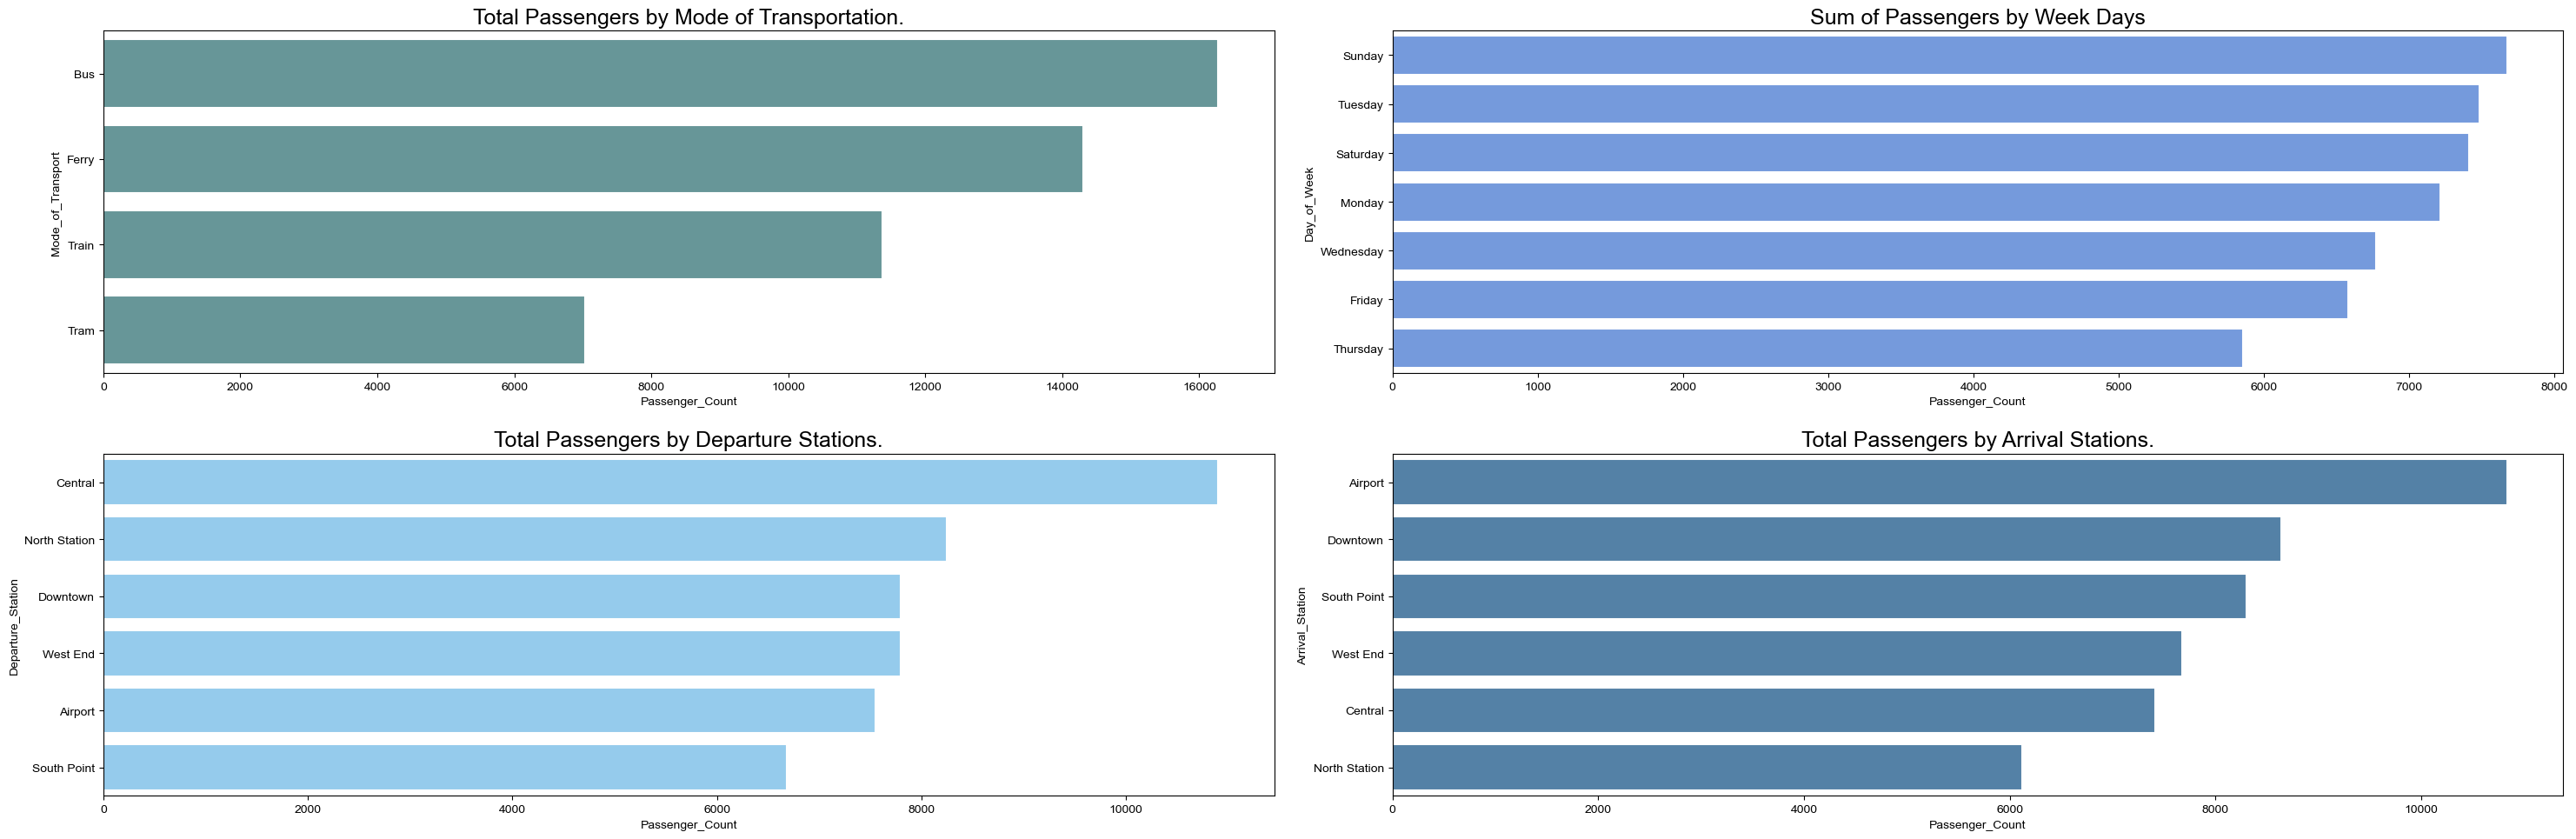

In [59]:

fig, axs = plt.subplots(nrows=2, ncols=2, figsize=(30, 10))
sns.set(style="ticks", palette="inferno", font="Verdana", context="talk")

# Which Mode of Transportation is mostly used by passengers?
mot_passengers = df.groupby('Mode_of_Transport')['Passenger_Count'].sum().sort_values(ascending=False).reset_index()
sns.barplot(x='Passenger_Count', y='Mode_of_Transport', data=mot_passengers, ax=axs[0,0], color="cadetblue")
axs[0,0].set_title("Total Passengers by Mode of Transportation.")

# Which days of the Week do passengers travel the most?
weekly_demands = df.groupby('Day_of_Week')['Passenger_Count'].sum().sort_values(ascending=False).reset_index()
sns.barplot(x='Passenger_Count', y='Day_of_Week', data=weekly_demands, ax=axs[0,1], color='cornflowerblue')
axs[0,1].set_title('Sum of Passengers by Week Days')

# Which Departure Stations are mostly used by Passengers?
departure_passengers = df.groupby('Departure_Station')['Passenger_Count'].sum().sort_values(ascending=False).reset_index()
sns.barplot(x='Passenger_Count', y='Departure_Station', data=departure_passengers, ax=axs[1,0], color='lightskyblue')
axs[1,0].set_title('Total Passengers by Departure Stations.')

# Which Arrival Stations are mostly used by Passengers?
arrival_passengers = df.groupby('Arrival_Station')['Passenger_Count'].sum().sort_values(ascending=False).reset_index()
sns.barplot(x='Passenger_Count', y='Arrival_Station', data=arrival_passengers, ax=axs[1,1], color='steelblue')
axs[1,1].set_title('Total Passengers by Arrival Stations.')

plt.tight_layout()
plt.show()

### Insights:
- **Bus** has the **highest** total number of passenger useage among other mode of transportation.
- **Most** Passengers departed from **Central Station**
- **The Airpot** has the **highest** arrivals.
- **Sunday** has the highest total number of passengers.
- **Tram, South Point, Thursday and North Station** experienced fewest total number of passengers respectively.

#### 2. checking the Hour of day with most demand.

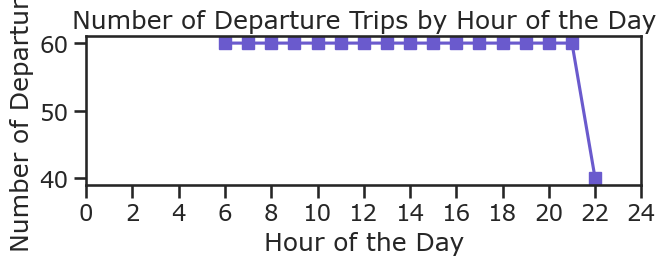

In [60]:
daily_hours = df.groupby('Departure_hour').size().sort_index()    # count all trips within each unique hour and sort/display chronologically.
sns.set(style="ticks", palette="inferno", font="Verdana", context="talk")
daily_hours.plot(figsize=(7,3), marker='s', color='slateblue')
plt.title('Number of Departure Trips by Hour of the Day')
plt.xlabel('Hour of the Day')
plt.ylabel('Number of Departures')
plt.xticks(range(0, 25, 2))
plt.tight_layout()
plt.show()

### Insight:
First departure trips starts at around 6:00 and the last at around 22:00
- Approximately **60 trips** takes place every hour from 6:00 am  to 21:00, with the least departure trips(**40 trips**) around 22:00

## Analyzing how trip characteristics impact customer experience.

#### 1. Comparing Average Trip Duration and Transport Fare

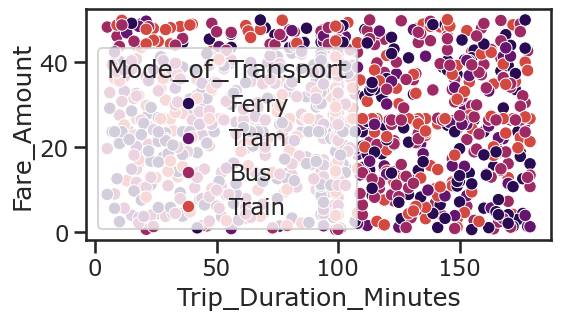

In [61]:
plt.figure(figsize=(6,3))
sns.scatterplot(data=df, x='Trip_Duration_Minutes', y='Fare_Amount',  hue='Mode_of_Transport');

### Insight:
There's no direct relationship/correlation between Trip Duration and Transport Fare.

#### 2. Correlation Analysis of all Numerical data

In [62]:
numeric_data = df.select_dtypes(include='number')

In [63]:
numeric_data.sample(2)

,Passenger_Count,Fare_Amount,Trip_Duration_Minutes,Departure_hour,Departure_Minutes,Arrival_hour
672,30,36.08,28.0,17,12,17.0
363,26,15.55,63.0,12,3,13.0


In [64]:
correlation_map = numeric_data.corr()

correlation_map

,Passenger_Count,Fare_Amount,Trip_Duration_Minutes,Departure_hour,Departure_Minutes,Arrival_hour
Passenger_Count,1.000000,0.013396,0.019488,-0.007529,-0.040919,-0.003594
Fare_Amount,0.013396,1.000000,-0.040827,0.008312,0.019017,0.003511
Trip_Duration_Minutes,0.019488,-0.040827,1.000000,-0.031421,-0.005887,0.129828
Departure_hour,-0.007529,0.008312,-0.031421,1.000000,-0.039337,0.982994
Departure_Minutes,-0.040919,0.019017,-0.005887,-0.039337,1.000000,0.025462
Arrival_hour,-0.003594,0.003511,0.129828,0.982994,0.025462,1.000000


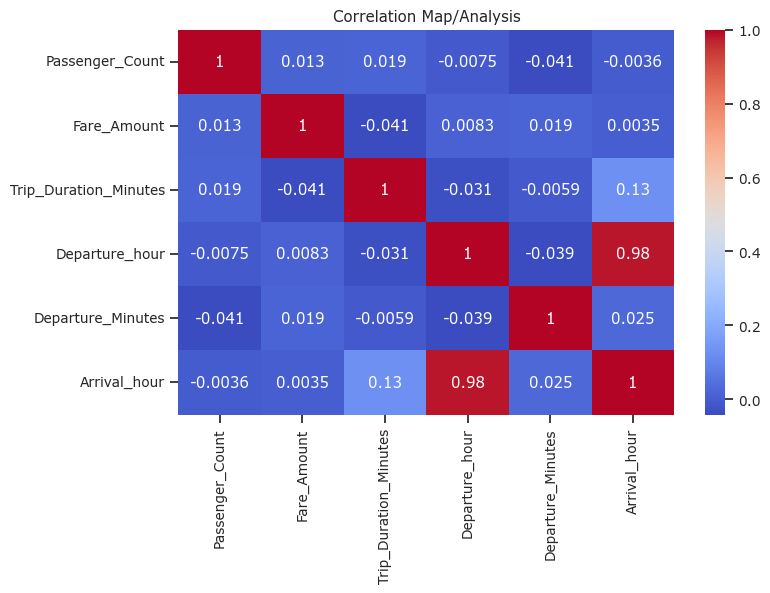

In [65]:
# Plot of correlation_map

plt.figure(figsize=(8, 5))
sns.set(style="ticks", palette="inferno", font="Verdana", font_scale=0.9)
sns.heatmap(correlation_map, annot=True, cmap='coolwarm')
plt.title("Correlation Map/Analysis")
plt.show()

### Insights:
 - There are generally very weak positive/negative correlations across numerical data.
 - However,**Departure Hour** has a `very strong` **positive correlation(0.98)** with **Arrival Hour**.

In [66]:
df.columns

Index(['Trip_ID', 'Mode_of_Transport', 'Departure_Station', 'Arrival_Station',
       'Departure_Time', 'Passenger_Count', 'Fare_Amount',
       'Trip_Duration_Minutes', 'Trip_Date', 'Day_of_Week', 'Trip_Year_Month',
       'Departure_hour', 'Departure_Minutes', 'Arrival_hour', 'Time_band',
       'Journey_Bands', 'Fare_Amount_Bands'],
      dtype='object')

#### 3. Checking the charcteristics of different Categorical Bands 

In [67]:
categorical_bands = ['Time_band', 'Journey_Bands', 'Fare_Amount_Bands']

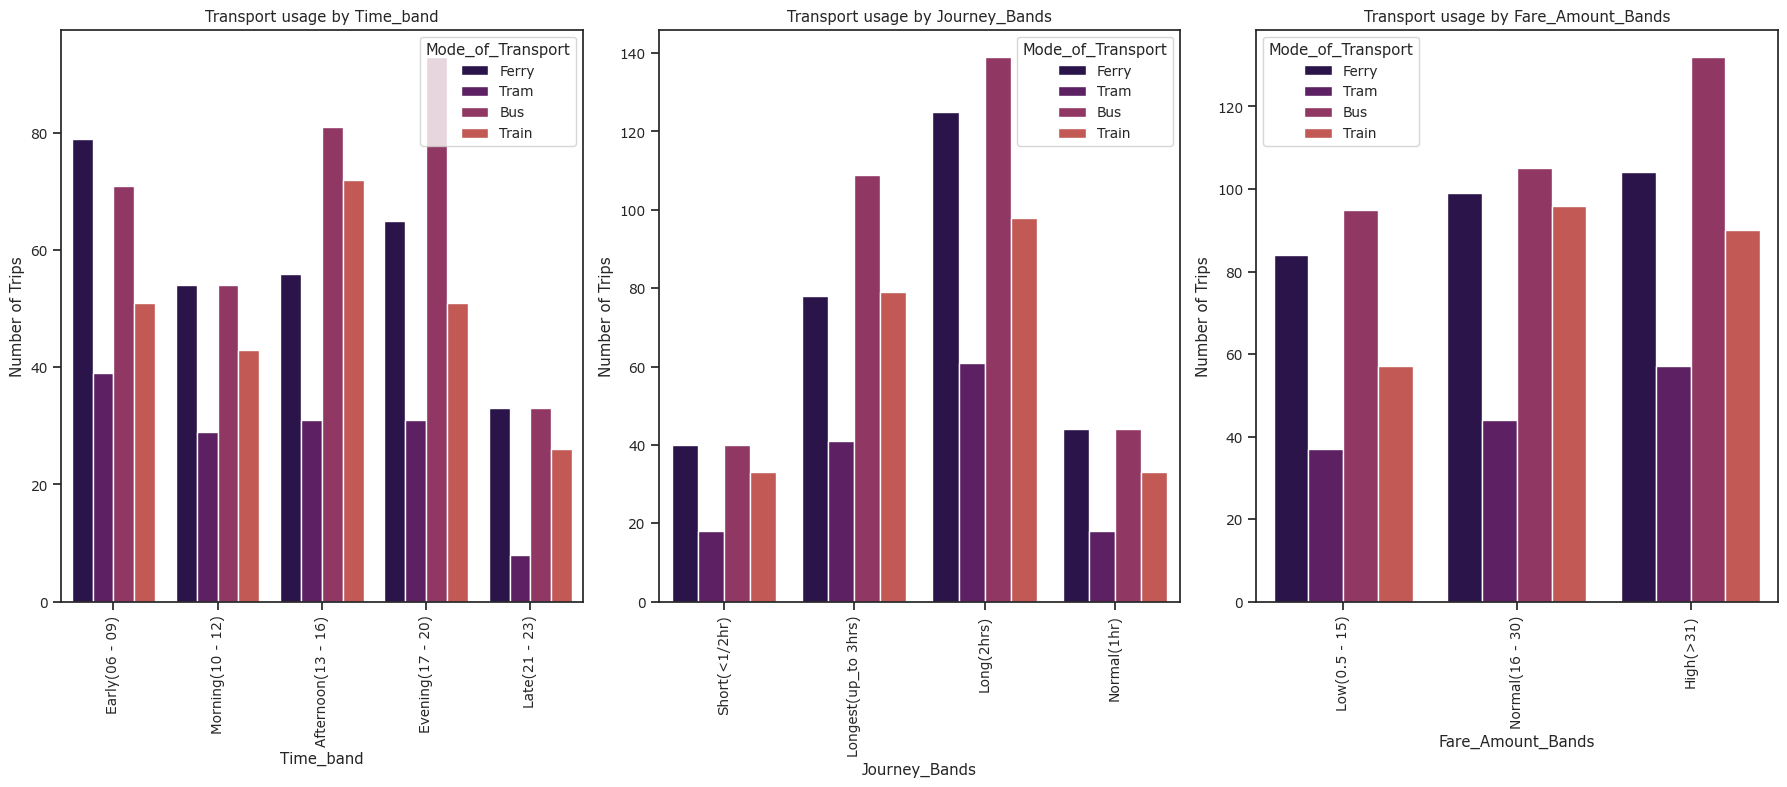

In [68]:
fig, axs = plt.subplots(nrows=1, ncols=3, figsize=(18, 8))
ax = axs.flatten()

for index, column_name in enumerate(categorical_bands):
    sns.countplot(data=df, x=column_name, ax=axs[index], hue='Mode_of_Transport')

    axs[index].set_title(f"Transport usage by {column_name}")
    axs[index].set_ylabel('Number of Trips')
    axs[index].tick_params(axis='x', rotation=90)
plt.tight_layout()
plt.show()

### Insights:
Each mode of transportation cuts across the various time bands, journey bands and fare amount bands.
- Highs:
  **Buses** have the most departures in the **Evening(17:00 - 20:00)**. It also characterized by many **Long journeys of up to 3 hours**.
  Buses also have the highest number of trips, also at the peak of **high Fare amounts of > £31**.
  - **Ferry** is most popular in the **early mornings (06:00-09:00)**. It also has a great number of trips across Journey bands and Fare bands.
- Lows:
  **Tram** has the lowest number of trips  across the various bands, with its fewest departures around **Late evenings(21:00-23:00)**

## Evaluating the performance of different transport modes.

#### 1. Hourly Passenger usage in 'Arrival' and 'Departure' Stations for various Modes of Transportation

In [69]:
bus = df[df['Mode_of_Transport']=='Bus']
ferry = df[df['Mode_of_Transport']=='Ferry']
train = df[df['Mode_of_Transport']=='Train']
tram = df[df['Mode_of_Transport']=='Tram']

<function matplotlib.pyplot.show(close=None, block=None)>

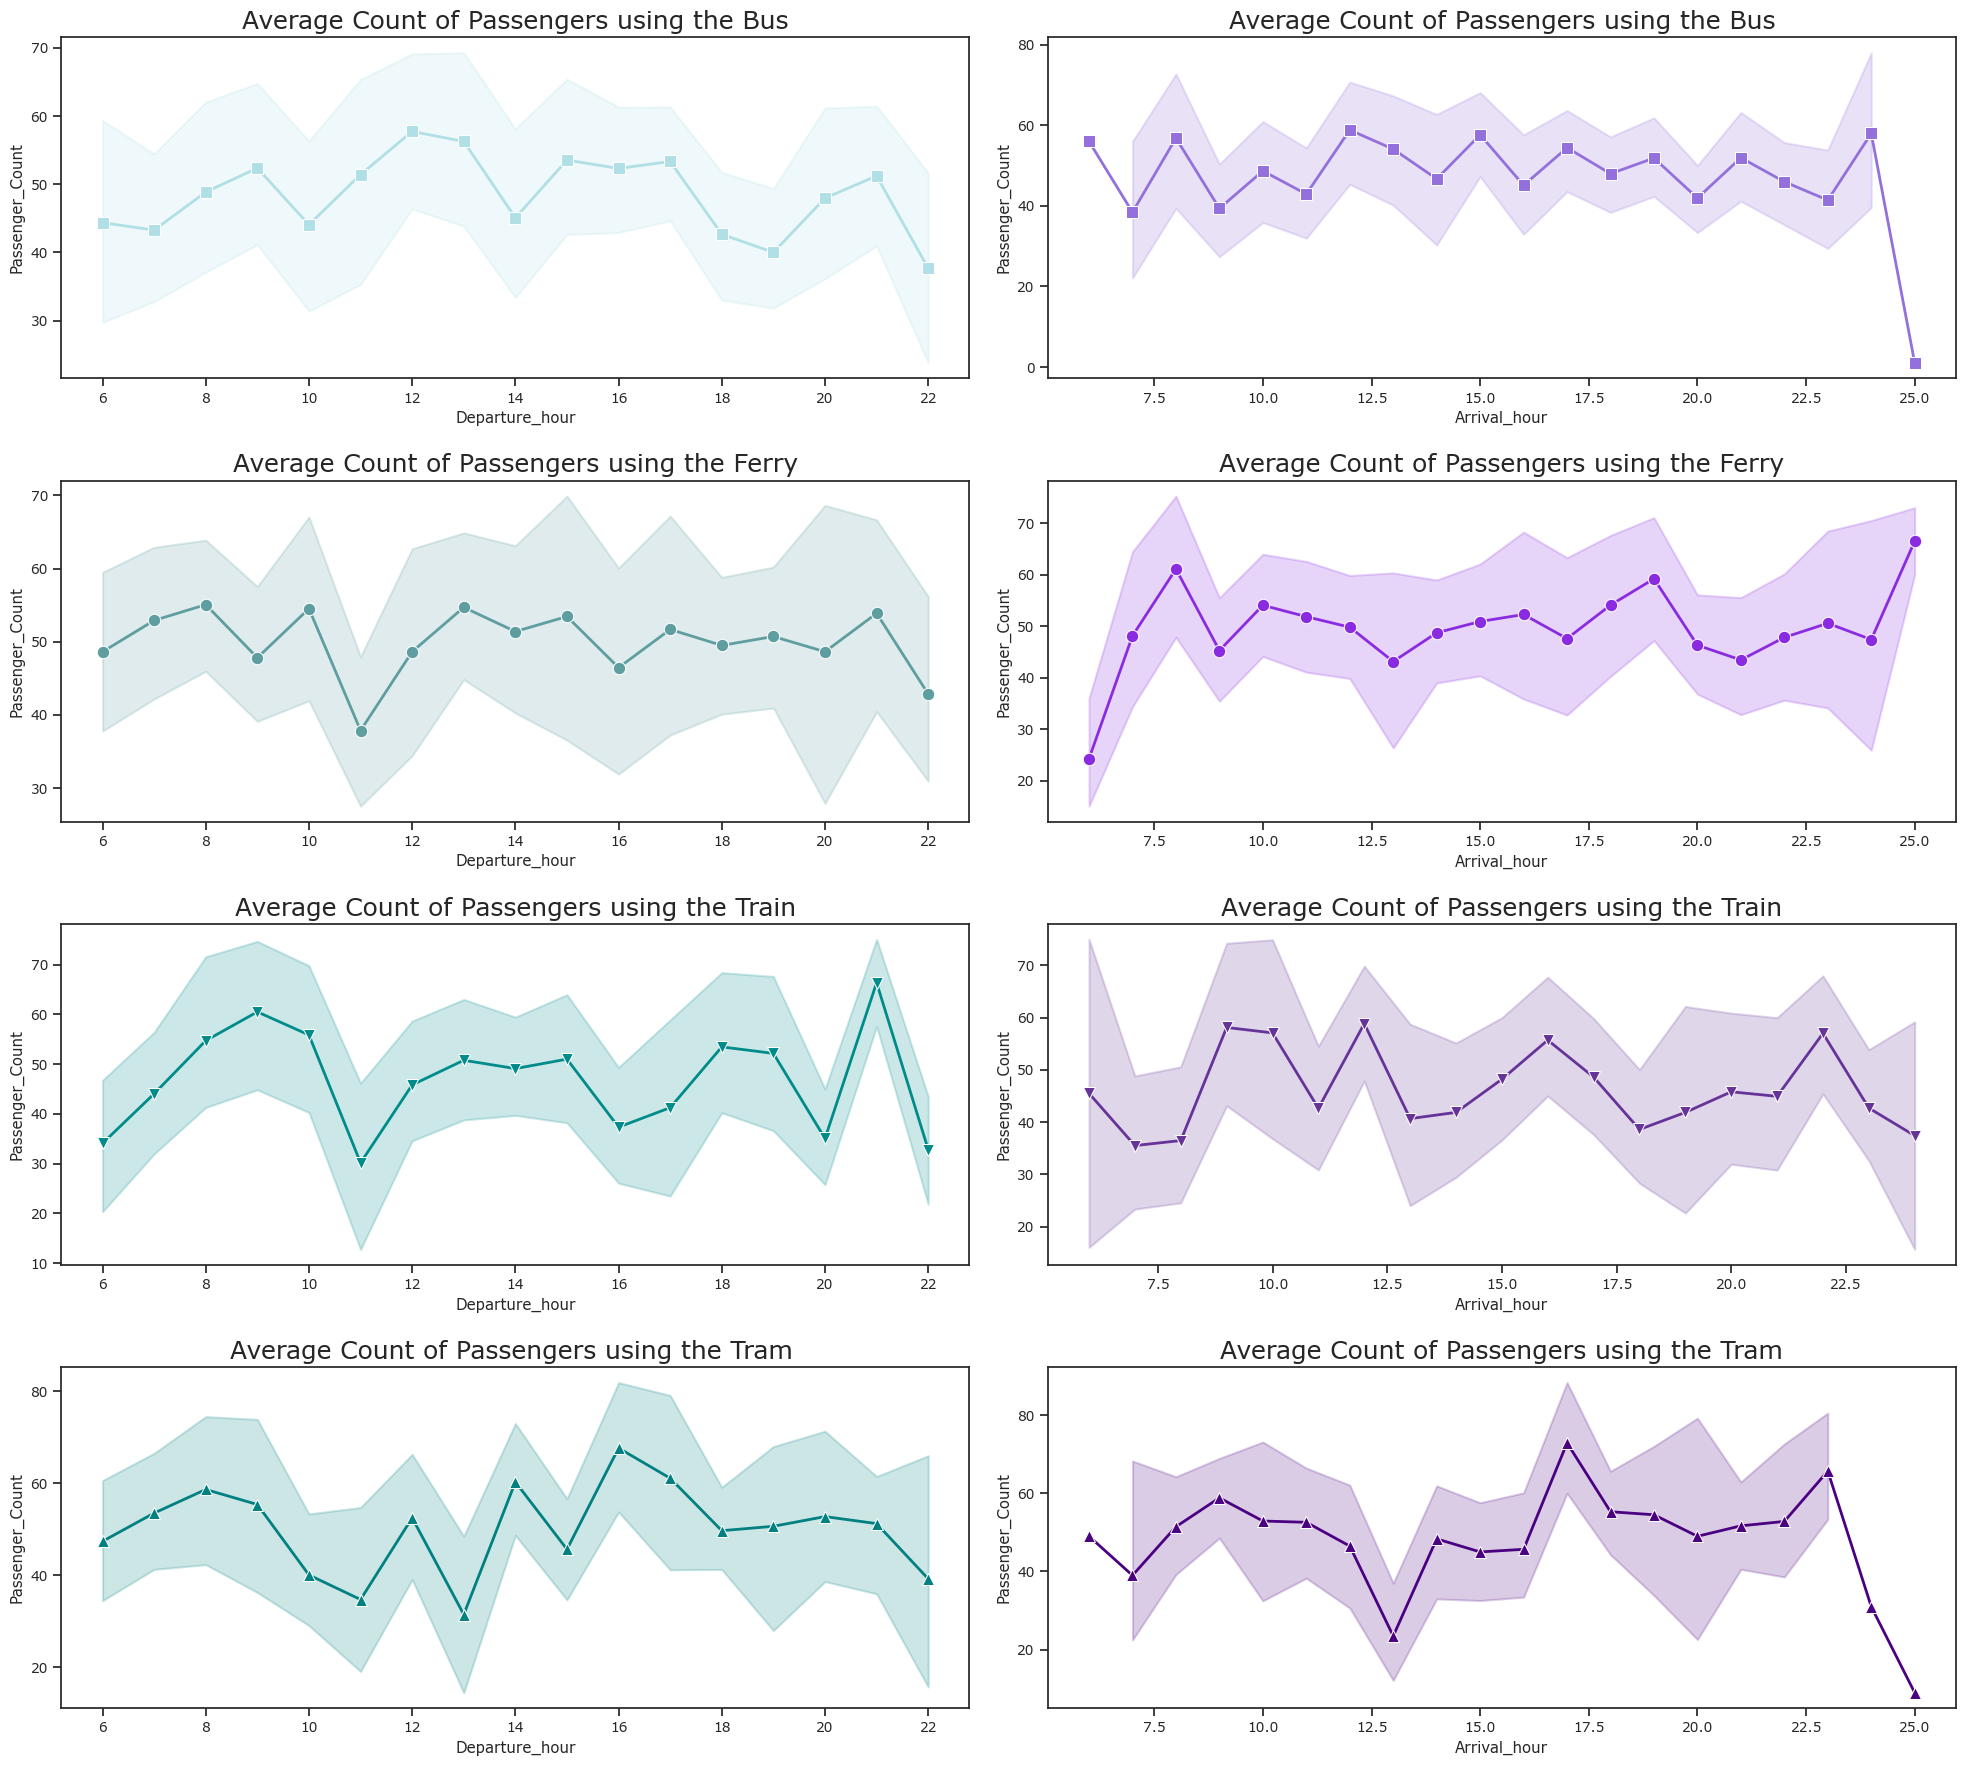

In [70]:
fig, axs = plt.subplots(nrows=4, ncols=2, figsize=(20,18))
sns.set(style="whitegrid", palette="inferno", font="Verdana", context="talk")

sns.lineplot(x="Departure_hour", y="Passenger_Count", data=bus, ax=axs[0,0], color='powderblue', marker="s", linewidth=2);
axs[0,0].set_title("Average Count of Passengers using the Bus")

sns.lineplot(x="Arrival_hour", y="Passenger_Count", data=bus, ax=axs[0,1], color='mediumpurple', marker="s", linewidth=2);
axs[0,1].set_title("Average Count of Passengers using the Bus")

sns.lineplot(x="Departure_hour", y="Passenger_Count", data=ferry, ax=axs[1,0], color='cadetblue', marker="o", linewidth=2);
axs[1,0].set_title("Average Count of Passengers using the Ferry")

sns.lineplot(x="Arrival_hour", y="Passenger_Count", data=ferry, ax=axs[1,1], color='blueviolet', marker="o", linewidth=2);
axs[1,1].set_title("Average Count of Passengers using the Ferry")

sns.lineplot(x="Departure_hour", y="Passenger_Count", data=train, ax=axs[2,0], color='darkcyan', marker="v", linewidth=2);
axs[2,0].set_title("Average Count of Passengers using the Train")

sns.lineplot(x="Arrival_hour", y="Passenger_Count", data=train, ax=axs[2,1], color='rebeccapurple', marker="v", linewidth=2);
axs[2,1].set_title("Average Count of Passengers using the Train")

sns.lineplot(x="Departure_hour", y="Passenger_Count", data=tram, ax=axs[3,0], color='teal', marker="^", linewidth=2)
axs[3,0].set_title("Average Count of Passengers using the Tram ")

sns.lineplot(x="Arrival_hour", y="Passenger_Count", data=tram, ax=axs[3,1], color='indigo', marker="^", linewidth=2);
axs[3,1].set_title("Average Count of Passengers using the Tram")

plt.tight_layout()
plt.show

### Insights:
-  Different modes of transport experience varying peak and off-peak periods throughout the day, indicating differences in passenger travel patterns.
- On Departures, **All** experience notably **off-peak periods between 10:00-12:00**. **Trams** also have most off-peak periods around 13:00.
- **Trains** have their peak times around **09:00 and 21:00**
- Last arrival trips for all modes of transportation are around **02:00 a.m**

### 2. Summary of Different Modes of Transportation

In [71]:
MOT_summary = df.groupby(df['Mode_of_Transport']).agg(
    Total_Passengers = ('Passenger_Count', 'sum'),
    Total_Fare_Amount = ('Fare_Amount', 'sum'),
    Typical_Fare_Amount = ('Fare_Amount', 'median'),
    Average_Trip_Duration = ('Trip_Duration_Minutes', 'mean')
)

MOT_summary["MOT_value_pct"] = (MOT_summary['Total_Fare_Amount']/MOT_summary['Total_Fare_Amount'].sum())*100
MOT_summary.sort_values('Total_Fare_Amount', ascending=False).round()

,Total_Passengers,Total_Fare_Amount,Typical_Fare_Amount,Average_Trip_Duration,MOT_value_pct
Mode_of_Transport,,,,,
Bus,16280,8529.0,26.0,97.0,34.0
Ferry,14304,6978.0,24.0,92.0,27.0
Train,11369,6393.0,27.0,95.0,25.0
Tram,7034,3484.0,25.0,95.0,14.0


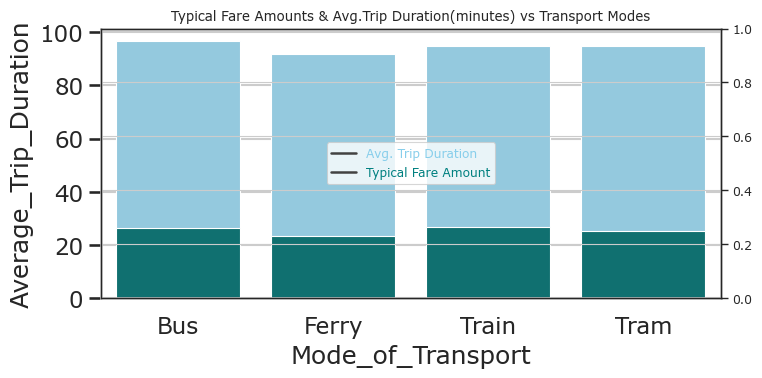

In [72]:
# Typical Fare Amount and Average Trip duration in minutes of various mode of transportation

fig, ax = plt.subplots(figsize=(8,3.5))
sns.set(style="ticks", palette="inferno", font="Verdana", context="paper")
sns.barplot(x='Mode_of_Transport', y='Average_Trip_Duration', data=MOT_summary, color='skyblue')
sns.barplot(x='Mode_of_Transport', y='Typical_Fare_Amount', data=MOT_summary, color='teal')
plt.legend(labels=['Avg. Trip Duration', 'Typical Fare Amount'], loc='center', labelcolor=['skyblue', 'teal'])
ax2 = ax.twinx()

plt.title("Typical Fare Amounts & Avg.Trip Duration(minutes) vs Transport Modes")
plt.grid(True)
plt.show()

### Insight:
**Ferry** has the shortest average trip durations(in minutes). It is also the most affordable, with typical fare amounts of approx. **£24**
while the **Bus** has the longest average trip durations.

#### Best Value Mode of Transportation

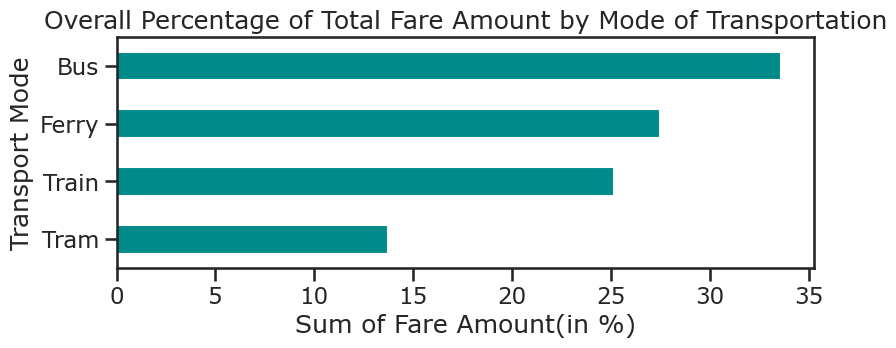

In [73]:
best_value = MOT_summary["MOT_value_pct"].sort_values()

sns.set(style="ticks", palette="inferno", font="Verdana", context="talk")
best_value.plot(kind='barh', color='darkcyan', figsize=(9, 3))
plt.title("Overall Percentage of Total Fare Amount by Mode of Transportation")
plt.xlabel("Sum of Fare Amount(in %)")
plt.ylabel("Transport Mode")
plt.show()

### Insight:
- **Most passengers(16,280 persons)** use **Bus** as a mode of transportation. It also provides the best value with approximately **34%** of the total fare amounts.
- **Trams** are the least used by passengers and it accounts for approximately **14%** of total fare amounts.


## Summary of Findings
#### Observation
Column "Unnamed: 11" has 299 non-null values out of 999 expected. Nothing much can be extracted from it.
- "Unnamed: 11" & "Unnamed: 10"  will be dropped/deleted.
- **Bus** is the most frequent mode of transportation, while the least is **Tram**
- **Central** experienced the highest number of transportation departures while **South Point** has the least
- **Airport** has the highest number of arrivals, while **North Station** has the least arrivals.
- Columns with missing data are Passenger_Count, Fare_Amount, Trip_Duration_Minutes
- About 10% of the data are missing in each column and are also evenly distributed across the entire dataset
- **`Early(06:00 - 09:00)`, `Afternoon(13:00 - 16:00)` and `Evening(17:00 - 20:00)`**  all have the highest and equal counts ofdeparture trips(**total of 240**).
- While the fewest trips took place **late evenings (21:00 - 23:00)**

- **Bus** has the **highest** total number of passenger usage among other modes of transportation.
- **Most** Passengers departed from **Central Station**
- **The Airpot** has the **highest** arrivals.
- **Sunday** has the highest total number of passengers.
- **Tram, South Point, Thursday and North Station** experienced the fewest total number of passengers, respectively.
- First departure trips start at around 6:00 and the last at around 22:00
- Approximately 60 trips take place every hour from 6:00 am to 21:00, with the fewest departure trips(40 trips) around 22:00
- There's no direct relationship/correlation between Trip Duration and Transport Fare.
- There are generally very weak positive/negative correlations across numerical data.
- However,**Departure Hour** has a `very strong` **positive correlation(0.98)** with **Arrival Hour**.

- Each mode of transportation cuts across the various time bands, journey bands and fare amount bands.
- Highs:
  **Buses** have the most departures in the **Evening(17:00 - 20:00)**. It also characterized by many **Long journeys of up to 3 hours**.
  Buses also have the highest number of trips, also at the peak of **high Fare amounts of > £31**.
  - **Ferry** is most popular in the **early mornings (06:00-09:00)**. It also has a great number of trips across Journey bands and Fare bands.
- Lows:
  **Tram** has the lowest number of trips  across the various bands, with its fewest departures around **Late evenings(21:00-23:00)**

- Different modes of transport experience varying peak and off-peak periods throughout the day, indicating differences in passenger travel patterns.
- On Departures, **All** experience notably **off-peak periods between 10:00-12:00**. **Trams** also have most off-peak periods around 13:00.
- **Trains** have their peak times around **09:00 and 21:00**
- Last arrival trips for all modes of transportation are around **02:00 a.m**
- **Ferry** has the shortest average trip durations(in minutes). It is also the most affordable, with typical fare amounts of approx. **£24**
while the **Bus** has the longest average trip durations.

- **Most passengers(16,280 persons)** use the bus as a mode of transportation. It also provides the **best** value with approximately **34%** of the total fare amounts.
- **Trams** are the least used by passengers and it accounts for approximately **14%** of total fare amounts.
  

## Limitations
- Missing data
- Less data; additional dates to help indicate any seasonality.
- Average waiting times; clear metrics for Cost of Fares per passenger and Distance of travel
- No clear indication of Transport capacities

# Final Recomendations

#### Evaluate service frequency and capacity during identified peak periods, particularly for **trains** around 9a.m. and 9 p.m., **buses** around 12 noon, and trams during afternoon/evening peaks.
#### Reduce service frequency during **off-peaks**
#### Invest more on **Buses** as it's most popular and offers the best overall value.

In [80]:
df.to_excel(r'Cleaned_public_transport_trips_EDA.xlsx', index=False)